<a href="https://colab.research.google.com/github/tovarrog24/Emergency-Department-Volume-and-Capacity/blob/main/code/exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Progress Report #1: Data Exploration
## Emergency Department Forecasting and Optimization

Group 2: Rogelio "Anthony" Tovar and Virgil Rogers

Dataset: *Emergency Department Volume and Capacity, 2021–2023*, published by the California Department of Health Care Access and Information (HCAI) and listed on Data.gov (https://catalog.data.gov/dataset/emergency-department-volume-and-capacity).

This notebook explores the dataset before we build models. It follows the six required tasks in order, plus the four-step EDA process (Process 6.5.1). Every code cell runs top to bottom with a single Run All.

## 0. Setup and Data Loading

We import the libraries used throughout the notebook and set a consistent plot style.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.1.0 | seaborn 0.13.2


The assignment requires the notebook to read the data from `../dataset`. The code below reads the local copy when the repository is cloned (`code/` and `dataset/` are sibling folders). When the notebook is opened in Colab directly from GitHub, that folder does not exist, so it falls back to the same file in our GitHub repository.

We read the file with `keep_default_na=False` and treat only empty cells as missing. Section 6.1 explains why: pandas' default would turn the text "N/A" in the `system` column into a false missing value.

In [2]:
LOCAL_PATH = Path("../dataset/ED.csv")
REPO_URL = ("https://raw.githubusercontent.com/tovarrog24/"
            "Emergency-Department-Volume-and-Capacity/main/dataset/ED.csv")

source = LOCAL_PATH if LOCAL_PATH.exists() else REPO_URL
data = pd.read_csv(source, encoding="utf-8-sig", keep_default_na=False, na_values=[""])

# In this file "N/A" in the system column means the hospital is not part of a health system.
data["system"] = data["system"].replace("N/A", "No System")

print("Loaded from:", source)
data.head(3).T  # transposed so all 18 columns fit on the page

Loaded from: ../dataset/ED.csv


,0,1,2
oshpd_id,106010735,106010739,106010776
FacilityName2,Alameda Hospital,Alta Bates Summit Medical Center – Alta Bates ...,UC San Francisco Benioff Children's Hospital O...
CountyName,Alameda,Alameda,Alameda
system,Alameda Health System,Sutter Health,No System
year,2022,2022,2022
LICENSED_BED_SIZE,100-149,300-499,150-199
HospitalOwnership,Government,Nonprofit,Nonprofit
UrbanRuralDesi,Urban,Urban,Urban
TEACHINGDesignation,Non-Teaching,Non-Teaching,Teaching
Category,Active COVID-19,Active COVID-19,Active COVID-19


### 0.1 How the data is structured

Before analyzing anything, we need to know what one row represents. The check below shows that each row is one hospital (`oshpd_id`) in one year for one of 17 diagnosis categories (`Category`). This is a "long" format. Hospital-level values such as `Tot_ED_NmbVsts` (total ED visits) and `EDStations` (ED treatment stations) repeat on all 17 rows for that hospital-year.

In [3]:
rows_per_hosp_year = data.groupby(["oshpd_id", "year"]).size()
print("Unique hospitals (oshpd_id):", data["oshpd_id"].nunique())
print("Unique hospital-years:      ", len(rows_per_hosp_year))
print("Rows per hospital-year:\n", rows_per_hosp_year.value_counts().sort_index(ascending=False).to_string())

hosp_cols = ["Tot_ED_NmbVsts", "EDStations"]
constant = data.groupby(["oshpd_id", "year"])[hosp_cols].nunique(dropna=False).eq(1).all()
print("\nConstant within each hospital-year:\n", constant.to_string())

all_visits = data[data["Category"] == "All ED Visits"]
print("\n'All ED Visits' EDDXCount equals Tot_ED_NmbVsts:",
      (all_visits["EDDXCount"] == all_visits["Tot_ED_NmbVsts"]).all())

vps_check = np.isclose(data["Visits_Per_Station"], data["EDDXCount"] / data["EDStations"], equal_nan=True).all()
print("Visits_Per_Station equals EDDXCount / EDStations:", vps_check)

Unique hospitals (oshpd_id): 297
Unique hospital-years:       757
Rows per hospital-year:
 17    741
16     12
15      4

Constant within each hospital-year:
 Tot_ED_NmbVsts    True
EDStations        True

'All ED Visits' EDDXCount equals Tot_ED_NmbVsts: True
Visits_Per_Station equals EDDXCount / EDStations: True


The output confirms three facts that shape the rest of the project:

1. There are 297 hospitals and 757 hospital-years. Most hospital-years have all 17 category rows, but 16 hospital-years are missing one or two categories.
2. `Tot_ED_NmbVsts` and `EDStations` are constant within a hospital-year. Any statistic computed on all 12,849 rows counts each hospital about 17 times, which inflates counts and distorts distributions.
3. `Visits_Per_Station` is the category count divided by stations (`EDDXCount / EDStations`), not total visits per station. For the "All ED Visits" row, it equals total visits per station.

We also check whether the 16 condition categories split total visits into separate pieces.

In [4]:
conditions = data[data["Category"] != "All ED Visits"]
condition_sum = conditions.groupby(["oshpd_id", "year"])["EDDXCount"].sum()
total = all_visits.set_index(["oshpd_id", "year"])["EDDXCount"]
share = (condition_sum / total).dropna()

print(share.describe().round(2).to_string())
print("\nShare of hospital-years where the condition sum exceeds total visits:", round((share > 1).mean(), 3))

count    757.00
mean       0.60
std        0.20
min        0.08
25%        0.46
50%        0.61
75%        0.71
max        1.73

Share of hospital-years where the condition sum exceeds total visits: 0.03


The 16 condition counts add up to anywhere from 8% to 173% of total visits (median 61%). They are not mutually exclusive, since the sum sometimes exceeds the total, and they do not cover every visit. We therefore never add category counts together to estimate volume; we use `Tot_ED_NmbVsts` instead.

Based on this, we build a second dataframe, `hosp`, with one row per hospital-year. It carries the hospital-level features plus two derived features:

- `ED_Burden` = `Tot_ED_NmbVsts / EDStations`. This is HCAI's own measure of ED burden, which the dataset description defines as ED visits per available treatment station.
- `Bed_Size_Rank` = the ordinal rank (1–7) of the licensed bed size range, so bed size can be used in correlations.

From here on we use `hosp` for hospital-level questions and `data` for diagnosis-category questions.

In [5]:
BED_ORDER = ["1-49", "50-99", "100-149", "150-199", "200-299", "300-499", "500+"]

hosp_features = ["oshpd_id", "FacilityName2", "CountyName", "system", "year", "LICENSED_BED_SIZE",
                 "HospitalOwnership", "UrbanRuralDesi", "TEACHINGDesignation", "Tot_ED_NmbVsts",
                 "EDStations", "LATITUDE", "LONGITUDE", "PrimaryCareShortageArea",
                 "MentalHealthShortageArea"]

hosp = data.drop_duplicates(["oshpd_id", "year"])[hosp_features].reset_index(drop=True)
hosp["ED_Burden"] = hosp["Tot_ED_NmbVsts"] / hosp["EDStations"]
hosp["Bed_Size_Rank"] = hosp["LICENSED_BED_SIZE"].map({size: rank for rank, size in enumerate(BED_ORDER, start=1)})

print("hosp shape:", hosp.shape)
hosp.head(3).T

hosp shape: (757, 17)


,0,1,2
oshpd_id,106010735,106010739,106010776
FacilityName2,Alameda Hospital,Alta Bates Summit Medical Center – Alta Bates ...,UC San Francisco Benioff Children's Hospital O...
CountyName,Alameda,Alameda,Alameda
system,Alameda Health System,Sutter Health,No System
year,2022,2022,2022
LICENSED_BED_SIZE,100-149,300-499,150-199
HospitalOwnership,Government,Nonprofit,Nonprofit
UrbanRuralDesi,Urban,Urban,Urban
TEACHINGDesignation,Non-Teaching,Non-Teaching,Teaching
Tot_ED_NmbVsts,13579,29760,35062


## 1. Numerical and Categorical Features

We classify all 18 original features and list each one's range (numerical) or category values (categorical). Two classifications need explanation:

- `oshpd_id` is stored as an integer, but it is a facility identifier, so we treat it as categorical (nominal). Its arithmetic has no meaning.
- `LICENSED_BED_SIZE` is stored as text ranges such as "100-149", so it is categorical (ordinal), not numerical.

In [6]:
numerical = {
    "year": "Numerical (discrete)",
    "Tot_ED_NmbVsts": "Numerical (discrete count)",
    "EDStations": "Numerical (discrete count)",
    "EDDXCount": "Numerical (discrete count)",
    "LATITUDE": "Numerical (continuous)",
    "LONGITUDE": "Numerical (continuous)",
    "Visits_Per_Station": "Numerical (continuous ratio)",
}
categorical = {
    "oshpd_id": "Categorical (nominal identifier)",
    "FacilityName2": "Categorical (nominal)",
    "CountyName": "Categorical (nominal)",
    "system": "Categorical (nominal)",
    "LICENSED_BED_SIZE": "Categorical (ordinal)",
    "HospitalOwnership": "Categorical (nominal)",
    "UrbanRuralDesi": "Categorical (ordinal)",
    "TEACHINGDesignation": "Categorical (binary)",
    "Category": "Categorical (nominal)",
    "PrimaryCareShortageArea": "Categorical (binary)",
    "MentalHealthShortageArea": "Categorical (binary)",
}

rows = []
for col, kind in numerical.items():
    low, high = data[col].min(), data[col].max()
    if col == "year":
        span = f"{low} to {high}"
    elif col in ("LATITUDE", "LONGITUDE", "Visits_Per_Station"):
        span = f"{low:,.2f} to {high:,.2f}"
    else:
        span = f"{low:,.0f} to {high:,.0f}"
    rows.append([col, kind, span])
for col, kind in categorical.items():
    values = data[col].astype(str).unique()
    if col == "LICENSED_BED_SIZE":
        listing = ", ".join(BED_ORDER)
    elif col in ("oshpd_id", "FacilityName2"):
        listing = f"{len(values)} unique values (one per facility; names change for some IDs)"
    elif len(values) <= 17:
        listing = ", ".join(sorted(values))
    else:
        top = data[col].astype(str).value_counts().head(3).index
        listing = f"{len(values)} unique values; most frequent: " + "; ".join(top)
    rows.append([col, kind, listing])

feature_table = pd.DataFrame(rows, columns=["Feature", "Type", "Range / Category values"])
print(f"{len(numerical)} numerical and {len(categorical)} categorical features\n")
with pd.option_context("display.max_colwidth", 260):
    display(feature_table)

7 numerical and 11 categorical features



,Feature,Type,Range / Category values
0,year,Numerical (discrete),2021 to 2023
1,Tot_ED_NmbVsts,Numerical (discrete count),"511 to 146,799"
2,EDStations,Numerical (discrete count),1 to 114
3,EDDXCount,Numerical (discrete count),"0 to 146,799"
4,LATITUDE,Numerical (continuous),32.62 to 41.77
5,LONGITUDE,Numerical (continuous),-124.20 to -114.60
6,Visits_Per_Station,Numerical (continuous ratio),"0.00 to 4,714.00"
7,oshpd_id,Categorical (nominal identifier),297 unique values (one per facility; names change for some IDs)
8,FacilityName2,Categorical (nominal),315 unique values (one per facility; names change for some IDs)
9,CountyName,Categorical (nominal),53 unique values; most frequent: Los Angeles; Orange; San Bernardino


The dataset has 7 numerical and 11 categorical features. A few points matter for later modeling:

- The numerical features cover a wide range of scales: `Tot_ED_NmbVsts` runs from 511 to 146,799 visits, while `EDStations` runs from 1 to 114. Regression models will need scaling.
- All coordinates fall inside California (latitude 32.6° to 41.8° N, longitude −124.2° to −114.6°), which agrees with HCAI being a California agency.
- The years are 2021–2023 only. Three points in time are enough to describe change but are a weak basis for time-series forecasting.
- `UrbanRuralDesi` has a natural order (Urban, Rural, Frontier), and `LICENSED_BED_SIZE` has seven ordered ranges. Both can be encoded ordinally.
- There are 315 facility names but only 297 IDs, because some hospitals changed names during the period. `oshpd_id` is the reliable key.

## 2. Single Feature Plots

These plots use `hosp` (one row per hospital-year) so that each hospital-year counts once.

### 2.1 Histogram: total ED visits (`sns.histplot`)

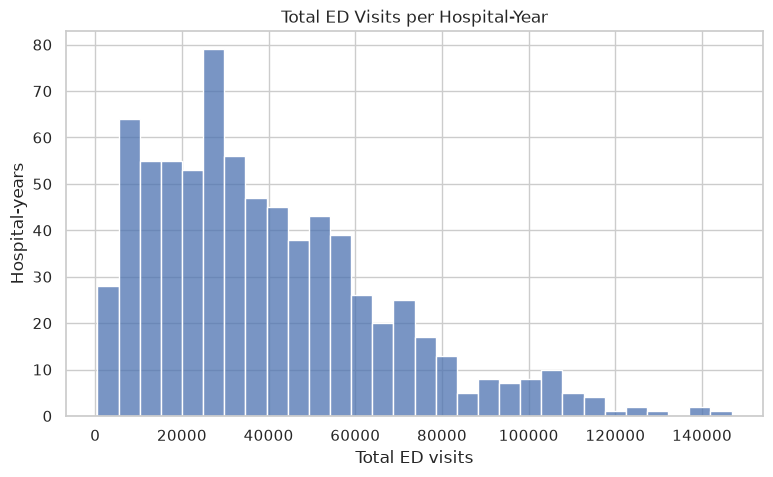

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(hosp, x="Tot_ED_NmbVsts", bins=30, ax=ax)
ax.set(title="Total ED Visits per Hospital-Year", xlabel="Total ED visits", ylabel="Hospital-years")
plt.show()

Most hospitals see about 10,000–60,000 ED visits a year. The tallest bar sits just below the median of 33,711. A long right tail runs past 100,000 visits. A small number of very high-volume EDs carry a large share of statewide demand, which supports our first learning question about which hospitals are used most.

### 2.2 Density plot: ED burden (`sns.kdeplot`)

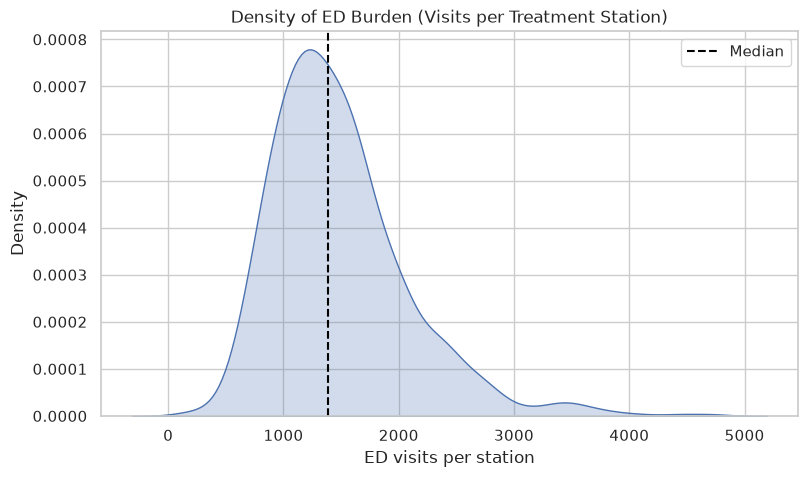

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(hosp, x="ED_Burden", fill=True, ax=ax)
ax.axvline(hosp["ED_Burden"].median(), color="black", linestyle="--", label="Median")
ax.set(title="Density of ED Burden (Visits per Treatment Station)", xlabel="ED visits per station")
ax.legend()
plt.show()

Burden peaks around 1,200–1,500 visits per station per year (median 1,385) and is right-skewed, with a thin tail past 3,000. Most EDs operate in a similar range, and a few run at two to three times the typical load. Those few are the facilities resource planning should look at first.

### 2.3 Count plot: licensed bed size (`sns.countplot`)

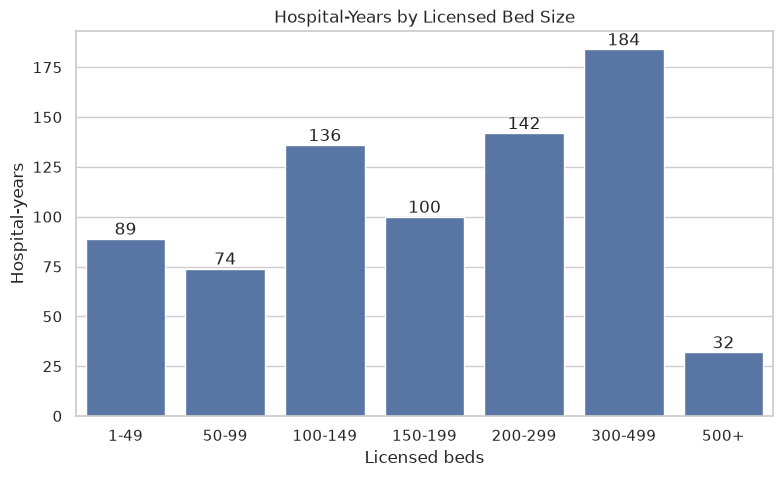

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(hosp, x="LICENSED_BED_SIZE", order=BED_ORDER, ax=ax)
ax.bar_label(ax.containers[0])
ax.set(title="Hospital-Years by Licensed Bed Size", xlabel="Licensed beds", ylabel="Hospital-years")
plt.show()

The 300–499 bed group is the largest (184 hospital-years), followed by 200–299 (142) and 100–149 (136). Only 32 hospital-years fall in the 500+ group. Because the groups are unbalanced, a classifier that predicts bed size would need class weighting or stratified sampling.

### 2.4 Box plot: ED treatment stations (`sns.boxplot`)

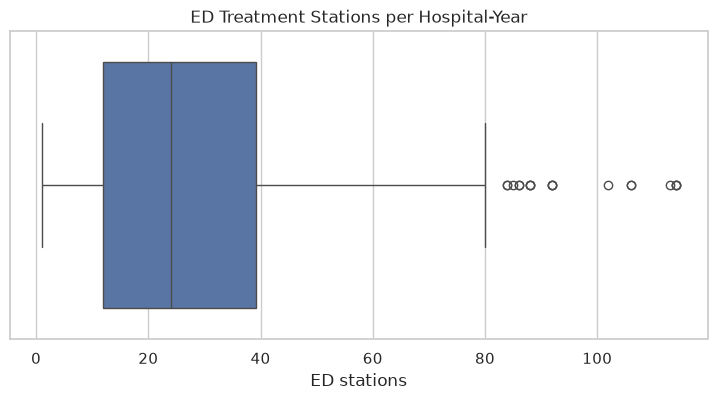

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(hosp, x="EDStations", ax=ax)
ax.set(title="ED Treatment Stations per Hospital-Year", xlabel="ED stations")
plt.show()

The middle 50% of EDs have between 12 and about 39 stations (median 24). Points beyond the upper whisker, above 80 stations, are the large regional EDs. The box sits to the left with a long right whisker, which is another right-skewed distribution.

### 2.5 Violin plot: hospital latitude (`sns.violinplot`)

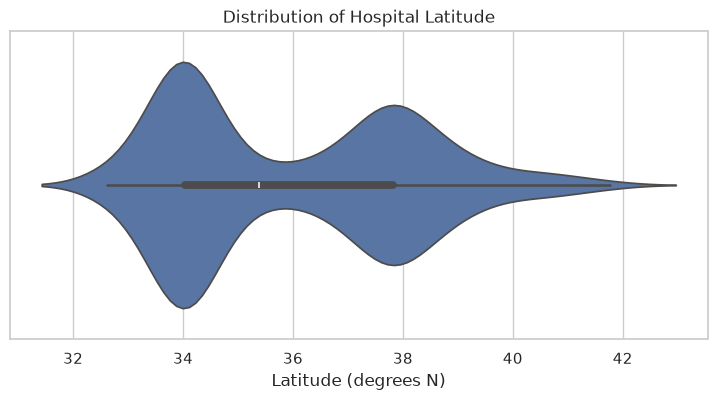

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.violinplot(hosp, x="LATITUDE", ax=ax)
ax.set(title="Distribution of Hospital Latitude", xlabel="Latitude (degrees N)")
plt.show()

Latitude is bimodal. One large cluster sits near 34° N, the Los Angeles and Southern California region, and a second sits near 37.5–38° N, the San Francisco Bay Area and Sacramento region. Hospitals are concentrated where people are, so any geographic heat map has to account for population density. That is why we will treat raw visit counts by area with caution.

## 3. Two Feature Plots

For the two-feature plots we use the most recent year, 2023 (252 hospitals), so that each hospital appears once and the points do not stack on top of each other.

### 3.1 Scatter plot: stations vs. visits (`sns.scatterplot` with `hue`, `style`, and `size`)

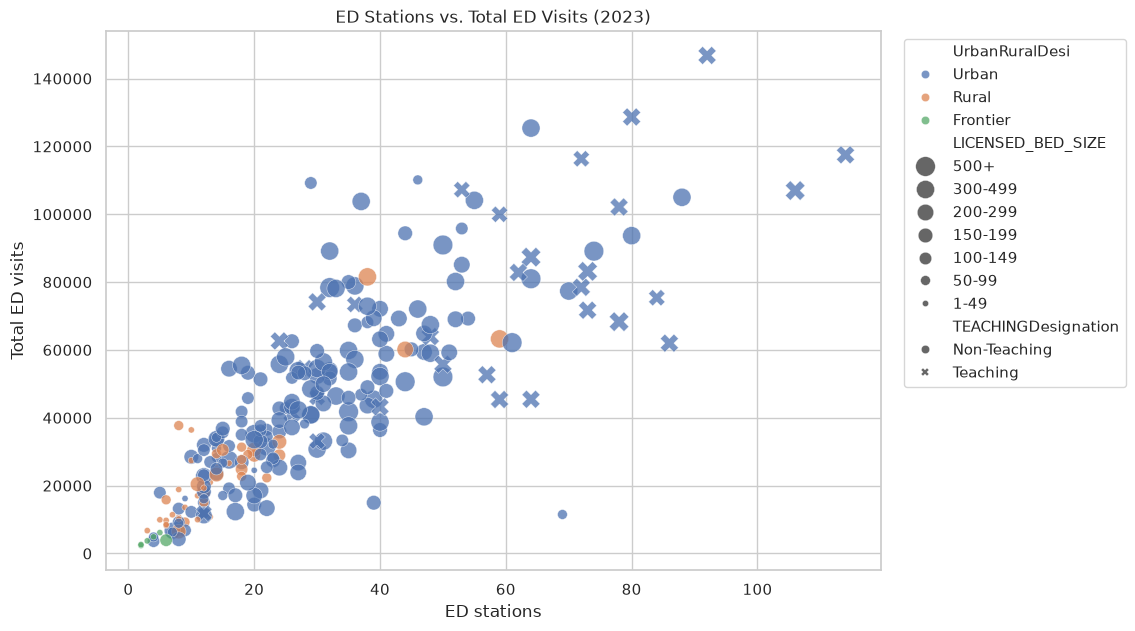

In [12]:
hosp_2023 = hosp[hosp["year"] == 2023].copy()

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(hosp_2023, x="EDStations", y="Tot_ED_NmbVsts",
                hue="UrbanRuralDesi", hue_order=["Urban", "Rural", "Frontier"],
                style="TEACHINGDesignation",
                size="LICENSED_BED_SIZE", size_order=BED_ORDER[::-1], sizes=(20, 200),
                alpha=0.75, ax=ax)
ax.set(title="ED Stations vs. Total ED Visits (2023)", xlabel="ED stations", ylabel="Total ED visits")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

Visits rise steadily with stations, so hospitals have generally sized their EDs to demand. Larger markers (more licensed beds) cluster in the upper right, and teaching hospitals (the alternate marker style) are mostly large urban facilities. Rural and frontier hospitals sit in the lower left with few stations and lower volume. Points well above the general trend are EDs handling more visits than their station count would suggest. That is the burden we measure directly in the next plot.

### 3.2 Scatter plot: geographic view (`sns.scatterplot` with `hue` and `size`)

This plot previews our second learning question (geographic patterns) by plotting longitude and latitude as a simple map.

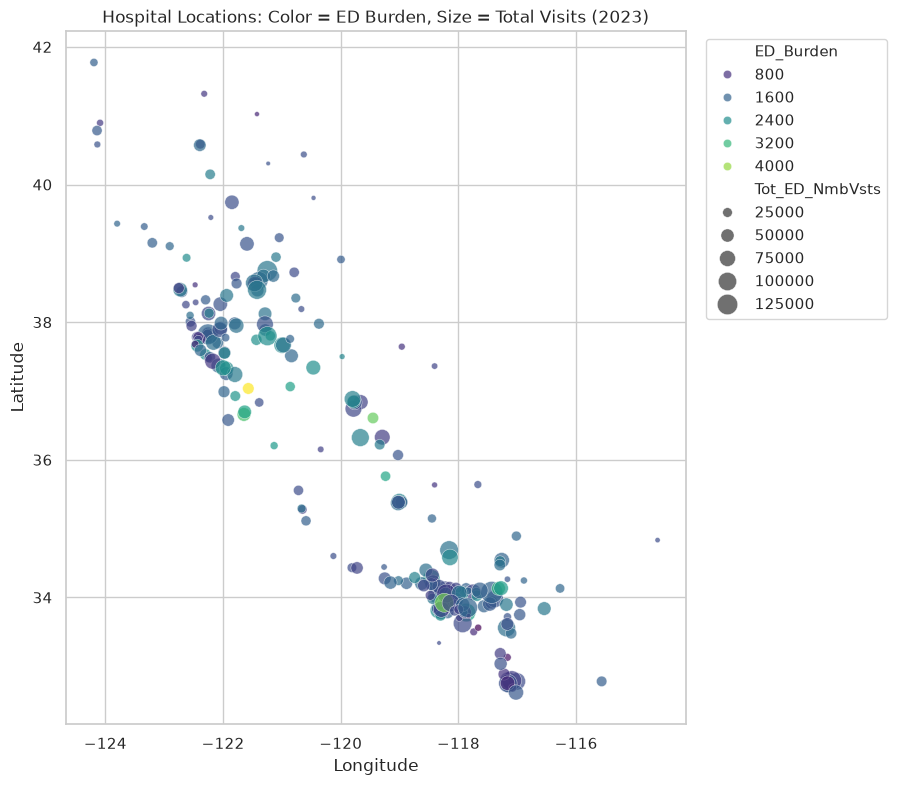

In [13]:
fig, ax = plt.subplots(figsize=(8, 9))
sns.scatterplot(hosp_2023, x="LONGITUDE", y="LATITUDE",
                hue="ED_Burden", palette="viridis",
                size="Tot_ED_NmbVsts", sizes=(10, 250), alpha=0.7, ax=ax)
ax.set(title="Hospital Locations: Color = ED Burden, Size = Total Visits (2023)",
       xlabel="Longitude", ylabel="Latitude")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

The plot traces the outline of California's population: dense clusters in Southern California and the Bay Area, a band through the Central Valley, and scattered points in the north and east. High-burden hospitals (lighter colors) are not limited to one region. They appear in Los Angeles as well as in the Central Valley and Central Coast. This suggests location alone does not explain burden, and later models should combine location with facility features.

### 3.3 Swarm plot: ED burden by ownership (`sns.swarmplot` with `hue` and `size`)

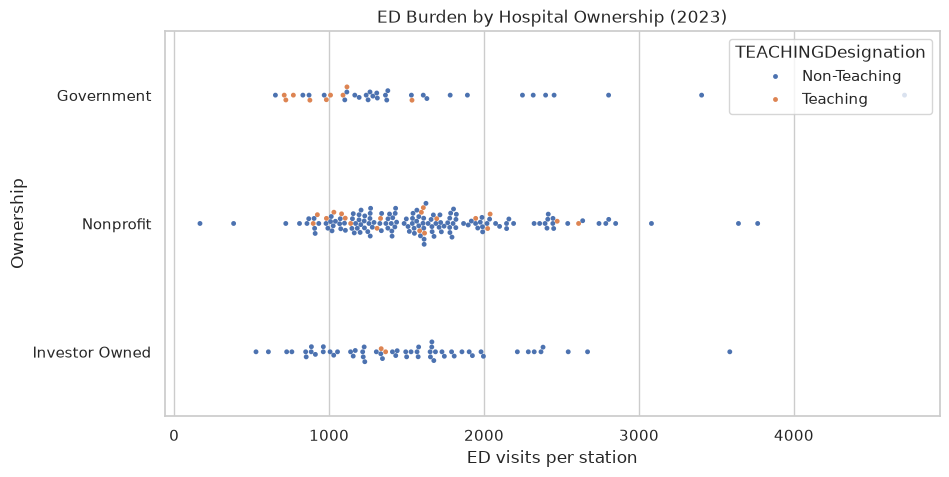

                   count  median
HospitalOwnership               
Government            38  1273.0
Investor Owned        58  1467.0
Nonprofit            156  1566.0


In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.swarmplot(hosp_2023, x="ED_Burden", y="HospitalOwnership", hue="TEACHINGDesignation",
              hue_order=["Non-Teaching", "Teaching"], size=3.5, ax=ax)
ax.set(title="ED Burden by Hospital Ownership (2023)", xlabel="ED visits per station", ylabel="Ownership")
plt.show()

print(hosp_2023.groupby("HospitalOwnership")["ED_Burden"].agg(["count", "median"]).round(0))

Each dot is one hospital. All three ownership types overlap heavily, so ownership by itself is a weak predictor of burden. In 2023, government hospitals had the lowest median burden (1,273), compared with 1,467 for investor-owned and 1,566 for nonprofit hospitals. Teaching hospitals (orange) tend to fall at or below the middle of each group. Across all three years, teaching hospitals have a median burden of 1,084 visits per station compared with 1,410 for non-teaching hospitals. This means teaching hospitals have more stations relative to their volume, not that they are less busy overall.

### 3.4 Strip plot: visits per station by diagnosis category (`sns.stripplot` with `hue` and `size`)

This plot uses the category-level data (`data`) for 2023, since `Visits_Per_Station` is defined per category.

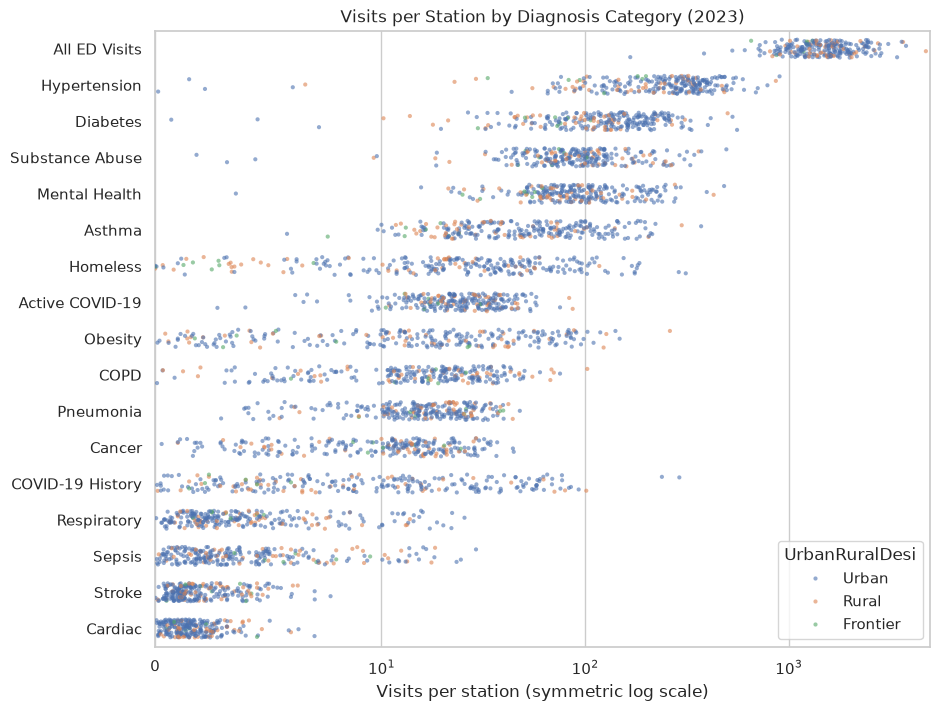

In [15]:
data_2023 = data[data["year"] == 2023]
category_order = (data_2023.groupby("Category")["Visits_Per_Station"].median()
                  .sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(10, 8))
sns.stripplot(data_2023, x="Visits_Per_Station", y="Category", order=category_order,
              hue="UrbanRuralDesi", hue_order=["Urban", "Rural", "Frontier"],
              size=3, alpha=0.6, jitter=0.25, ax=ax)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(left=0)
ax.set(title="Visits per Station by Diagnosis Category (2023)", xlabel="Visits per station (symmetric log scale)", ylabel="")
plt.show()

We used a symmetric log scale because category values range from 0 to over 4,000. After "All ED Visits," the conditions carrying the most load per station are hypertension (median about 270 per station in 2023), diabetes, substance abuse, and mental health. Stroke, cardiac, sepsis, and respiratory visits are far lower per station. Rural hospitals (orange) sit inside the urban spread for most categories, so condition mix looks broadly similar across settings. This category view gives us the "severity and type" dimension for the second learning question.

## Exploratory Data Analysis (Process 6.5.1)

### Step 1: Understand the data

In [16]:
print("Original data (one row per hospital-year-category):", data.shape)
print("Hospital-level data (one row per hospital-year):  ", hosp.shape)
print("\nNumerical features:  ", list(numerical))
print("Categorical features:", list(categorical))

Original data (one row per hospital-year-category): (12849, 18)
Hospital-level data (one row per hospital-year):   (757, 17)

Numerical features:   ['year', 'Tot_ED_NmbVsts', 'EDStations', 'EDDXCount', 'LATITUDE', 'LONGITUDE', 'Visits_Per_Station']
Categorical features: ['oshpd_id', 'FacilityName2', 'CountyName', 'system', 'LICENSED_BED_SIZE', 'HospitalOwnership', 'UrbanRuralDesi', 'TEACHINGDesignation', 'Category', 'PrimaryCareShortageArea', 'MentalHealthShortageArea']


The original data has 12,849 rows and 18 features: 7 numerical and 11 categorical, as listed in Section 1. Collapsing it to one row per hospital-year gives 757 rows. That smaller table is the correct unit for hospital-level analysis.

### Step 2: Identify relationships between features

We calculate Pearson correlations among the hospital-level numerical features. We include `Bed_Size_Rank` so bed size can be compared with the counts. We describe strength using a common rule of thumb: |r| ≥ 0.7 is strong, 0.3 to 0.7 is moderate, and below 0.3 is weak.

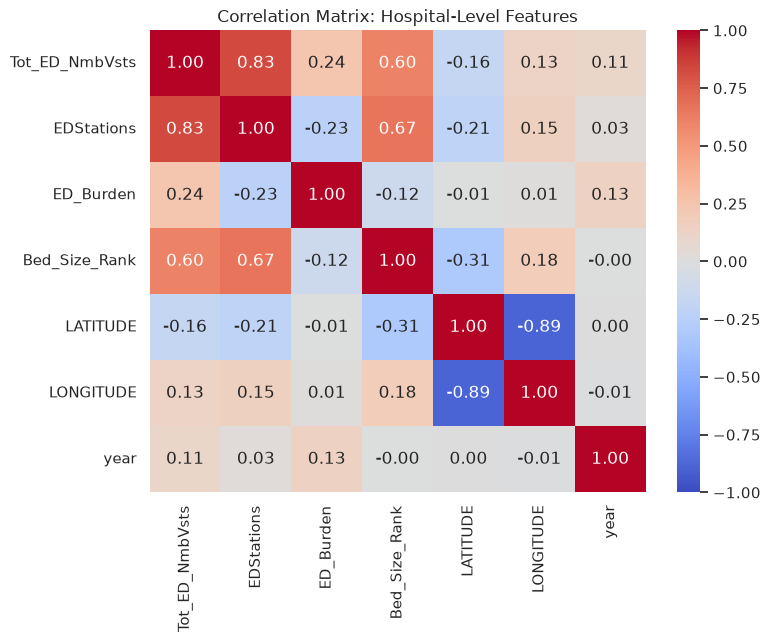

In [17]:
corr_cols = ["Tot_ED_NmbVsts", "EDStations", "ED_Burden", "Bed_Size_Rank", "LATITUDE", "LONGITUDE", "year"]
corr = hosp[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Matrix: Hospital-Level Features")
plt.show()

Key relationships:

- Visits and stations: strong positive (r = 0.83). Hospitals with more stations see more visits.
- Bed size with stations (0.67) and with visits (0.60): moderate positive. Larger hospitals have bigger and busier EDs. This answers the first part of our learning question 1: hospital size and usage are related, but not perfectly.
- ED burden with visits (0.24) and with stations (−0.23): weak in both directions. Burden is not explained by size, which makes it a useful separate target for modeling.
- Latitude and longitude: strong negative (−0.89). This reflects the northwest-to-southeast shape of California, not a relationship between hospital characteristics. We should not use both in a linear model without accounting for it.
- Year with burden: weak positive (0.13). Burden rose slightly from 2021 to 2023, which we quantify below.

In [18]:
yearly = hosp.groupby("year").agg(hospitals=("oshpd_id", "size"),
                                  total_visits=("Tot_ED_NmbVsts", "sum"),
                                  median_burden=("ED_Burden", "median")).round(0)
yearly

,hospitals,total_visits,median_burden
year,,,
2021,247,8819742,1274.0
2022,258,10375703,1387.0
2023,252,10788583,1505.0


Median burden rose from about 1,274 visits per station in 2021 to 1,505 in 2023. The number of hospitals reporting also changed each year (247, 258, 252), so statewide visit totals are not directly comparable year to year. Per-hospital measures such as burden are the fairer comparison.

### Step 3: Describe the shape of the data

We use skewness to describe shape: about −0.5 to 0.5 is roughly symmetric, 0.5 to 1 in absolute value is moderately skewed, and above 1 is highly skewed.

In [19]:
shape = pd.DataFrame({
    "skewness": [hosp["Tot_ED_NmbVsts"].skew(), hosp["EDStations"].skew(), hosp["ED_Burden"].skew(),
                 hosp["LATITUDE"].skew(), data["EDDXCount"].skew(), data["Visits_Per_Station"].skew()]},
    index=["Tot_ED_NmbVsts (hosp)", "EDStations (hosp)", "ED_Burden (hosp)",
           "LATITUDE (hosp)", "EDDXCount (data)", "Visits_Per_Station (data)"])
shape["shape"] = pd.cut(shape["skewness"].abs(), bins=[-np.inf, 0.5, 1, np.inf],
                        labels=["Approximately symmetric", "Moderately skewed", "Highly skewed"])
shape.round(2)

,skewness,shape
Tot_ED_NmbVsts (hosp),1.00,Highly skewed
EDStations (hosp),1.32,Highly skewed
ED_Burden (hosp),1.36,Highly skewed
LATITUDE (hosp),0.41,Approximately symmetric
EDDXCount (data),5.70,Highly skewed
Visits_Per_Station (data),4.62,Highly skewed


Every count-based feature is right-skewed. `ED_Burden` and `EDStations` are highly skewed (about 1.3), and `Tot_ED_NmbVsts` sits at the boundary (1.0). The category-level `EDDXCount` and `Visits_Per_Station` are extremely skewed (above 4.5) because they mix the "All ED Visits" total with small conditions such as stroke. Latitude is roughly symmetric overall, though Section 2.5 showed it is bimodal. For regression we will consider a log transform of the counts to reduce the influence of the large hospitals.

### Step 4: Detect outliers and missing data

In [20]:
print("Missing values in data:\n", data.isna().sum()[data.isna().sum() > 0].to_string())

def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    fence_low, fence_high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return series[(series < fence_low) | (series > fence_high)], fence_low, fence_high

print("\nIQR (1.5 x IQR) outliers in hosp:")
for col in ["Tot_ED_NmbVsts", "EDStations", "ED_Burden"]:
    flagged, low, high = iqr_outliers(hosp[col].dropna())
    print(f"  {col:15s} fences [{low:,.1f}, {high:,.1f}]  ->  {len(flagged)} hospital-years flagged")

Missing values in data:
 EDStations            17
Visits_Per_Station    17

IQR (1.5 x IQR) outliers in hosp:
  Tot_ED_NmbVsts  fences [-34,408.0, 107,912.0]  ->  16 hospital-years flagged
  EDStations      fences [-28.9, 80.1]  ->  18 hospital-years flagged
  ED_Burden       fences [66.2, 2,767.4]  ->  26 hospital-years flagged


Only `EDStations` has missing values: 17 rows, which is one hospital-year (Greater El Monte Community Hospital, 2022). `Visits_Per_Station` is missing on the same rows because it depends on stations. The IQR rule flags 16 hospital-years for high visits, 18 for many stations, and 26 for high burden. All of the flags are on the high side, as expected for right-skewed data. Section 6 examines these outliers by cause and explains how we handle each.

## 4. Dataset Summary

### 4.1 `df.shape`

In [21]:
print("data:", data.shape)
print("hosp:", hosp.shape)

data: (12849, 18)
hosp: (757, 17)


The original dataframe has 12,849 instances and 18 features. The hospital-level dataframe has 757 instances and 17 features (15 carried over plus `ED_Burden` and `Bed_Size_Rank`).

### 4.2 `df.info()`

In [22]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12849 entries, 0 to 12848
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   oshpd_id                  12849 non-null  int64  
 1   FacilityName2             12849 non-null  str    
 2   CountyName                12849 non-null  str    
 3   system                    12849 non-null  str    
 4   year                      12849 non-null  int64  
 5   LICENSED_BED_SIZE         12849 non-null  str    
 6   HospitalOwnership         12849 non-null  str    
 7   UrbanRuralDesi            12849 non-null  str    
 8   TEACHINGDesignation       12849 non-null  str    
 9   Category                  12849 non-null  str    
 10  Tot_ED_NmbVsts            12849 non-null  int64  
 11  EDStations                12832 non-null  float64
 12  EDDXCount                 12849 non-null  int64  
 13  LATITUDE                  12849 non-null  float64
 14  LONGITUDE        

All features are complete except `EDStations` and `Visits_Per_Station` (12,832 of 12,849 non-null). Four features are integers, four are floats, and ten are text. Because we read the file with explicit missing-value handling, `system` shows all 12,849 values present; pandas' default would have reported 3,590 missing (see Section 6.1).

### 4.3 `df.describe(include="all")`

In [23]:
data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
oshpd_id,12849.0,NaN,NaN,NaN,106283334.406958,138767.831347,106010735.0,106190392.0,106301234.0,106380939.0,106580996.0
FacilityName2,12849,315,Alameda Hospital,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CountyName,12849,53,Los Angeles,2885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
system,12849,32,No System,3590,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,12849.0,NaN,NaN,NaN,2022.006226,0.812108,2021.0,2021.0,2022.0,2023.0,2023.0
LICENSED_BED_SIZE,12849,7,300-499,3125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HospitalOwnership,12849,3,Nonprofit,7676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UrbanRuralDesi,12849,3,Urban,10019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TEACHINGDesignation,12849,2,Non-Teaching,11608,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,12849,17,Active COVID-19,757,NaN,NaN,NaN,NaN,NaN,NaN,NaN


For numerical features, the mean of `Tot_ED_NmbVsts` (39,642) sits well above its median (33,711), which confirms the right skew. `EDDXCount` has a median of 513 but a maximum of 146,799 because the "All ED Visits" rows are included. For categorical features, Los Angeles is the most frequent county, "No System" is the most frequent system value (3,590 rows, meaning independent hospitals), Nonprofit is the most common ownership, and Urban is the most common designation. Each of the 17 categories appears 753–757 times (Section 0.1), which confirms the balanced long structure. These statistics come from the 12,849-row data, so each hospital is weighted by its number of category rows. We use `hosp` for hospital-level statistics.

In [24]:
hosp[["Tot_ED_NmbVsts", "EDStations", "ED_Burden", "Bed_Size_Rank"]].describe().round(1)

,Tot_ED_NmbVsts,EDStations,ED_Burden,Bed_Size_Rank
count,757.0,756.0,756.0,757.0
mean,39609.0,28.6,1486.4,4.1
std,26949.9,20.8,598.1,1.8
min,511.0,1.0,166.6,1.0
25%,18962.0,12.0,1079.1,3.0
50%,33711.0,24.0,1385.0,4.0
75%,54542.0,39.2,1754.4,6.0
max,146799.0,114.0,4714.0,7.0


At the hospital-year level, the average ED sees 39,609 visits a year with 28.6 stations, an average burden of 1,486 visits per station. These are the figures we will cite when describing a typical California ED.

## 5. Many-Relationship Visualizations

We apply the pandas methods to the hospital-level numerical features, where each hospital-year counts once.

### 5.1 `df.hist()`

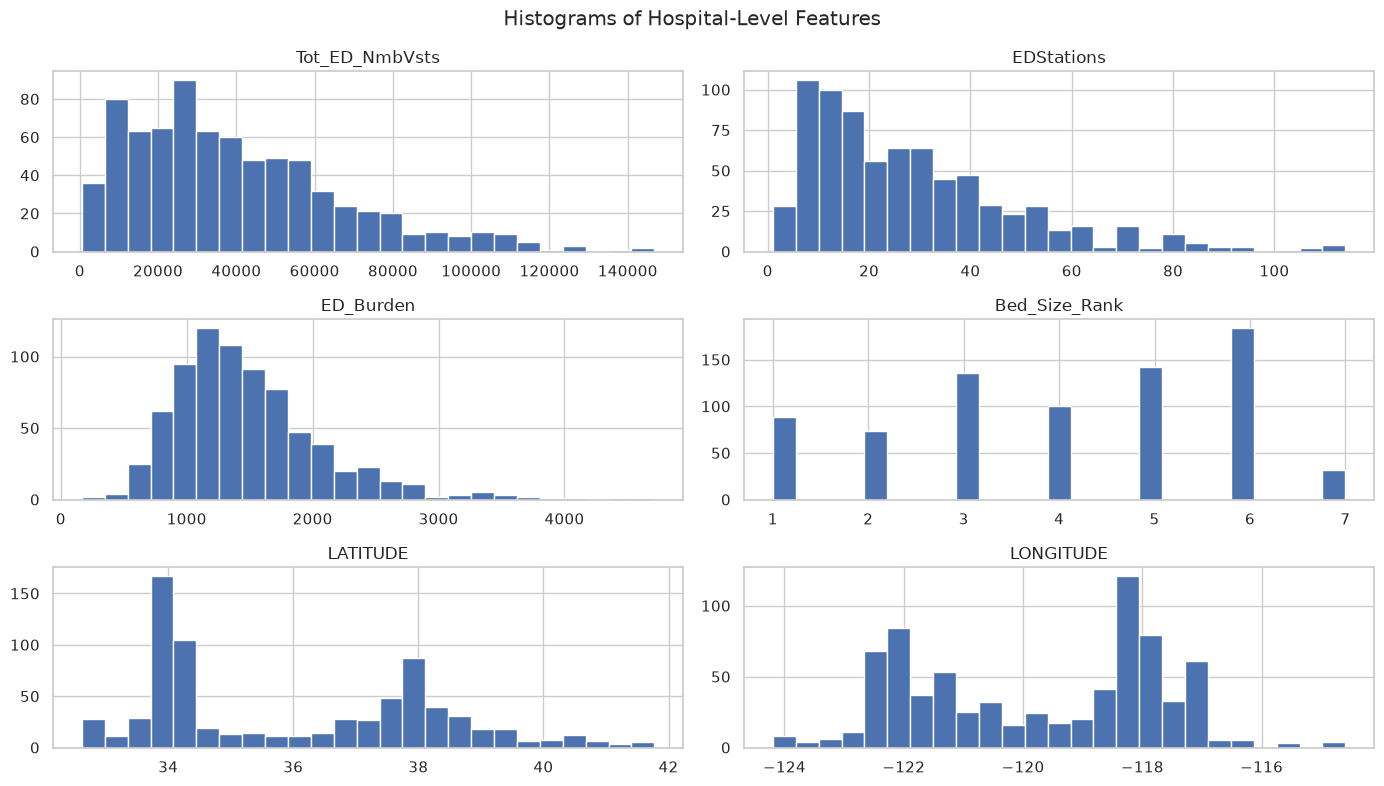

In [25]:
viz_cols = ["Tot_ED_NmbVsts", "EDStations", "ED_Burden", "Bed_Size_Rank", "LATITUDE", "LONGITUDE"]
axes = hosp[viz_cols].hist(figsize=(14, 8), bins=25)
plt.suptitle("Histograms of Hospital-Level Features")
plt.tight_layout()
plt.show()

The histograms show the right skew in visits, stations, and burden; the bimodal north/south pattern in latitude; and the ordered bed-size ranks peaking at rank 6 (300–499 beds). Longitude is concentrated between −122° and −117°, the Bay Area-to-Inland Empire corridor.

### 5.2 `df.boxplot()`

Visits, stations, and burden are on very different scales (tens of thousands vs. tens vs. thousands). We standardize them to z-scores first so all three boxes are readable on one axis.

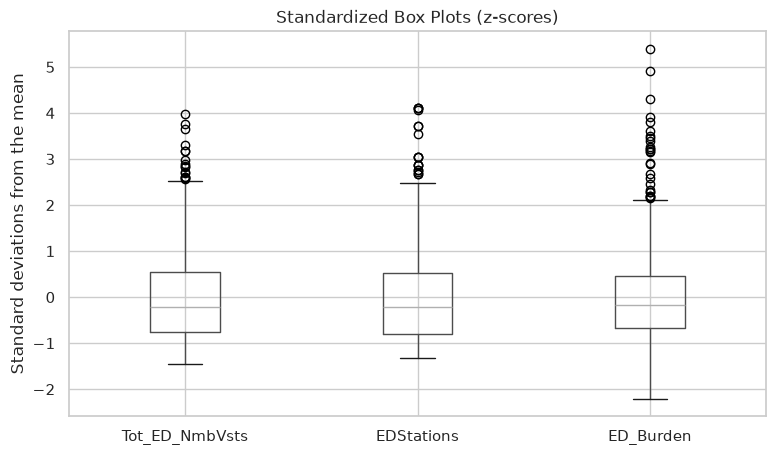

In [26]:
box_cols = ["Tot_ED_NmbVsts", "EDStations", "ED_Burden"]
standardized = (hosp[box_cols] - hosp[box_cols].mean()) / hosp[box_cols].std()

fig, ax = plt.subplots(figsize=(9, 5))
standardized.boxplot(ax=ax)
ax.set(title="Standardized Box Plots (z-scores)", ylabel="Standard deviations from the mean")
plt.show()

All three features have long upper tails and no low-side outliers. `ED_Burden` has the most extreme points, a little over 5 standard deviations above its mean. This matches the 26 IQR-flagged burden values from Step 4.

### 5.3 `pd.plotting.scatter_matrix()` and `sns.pairplot()`

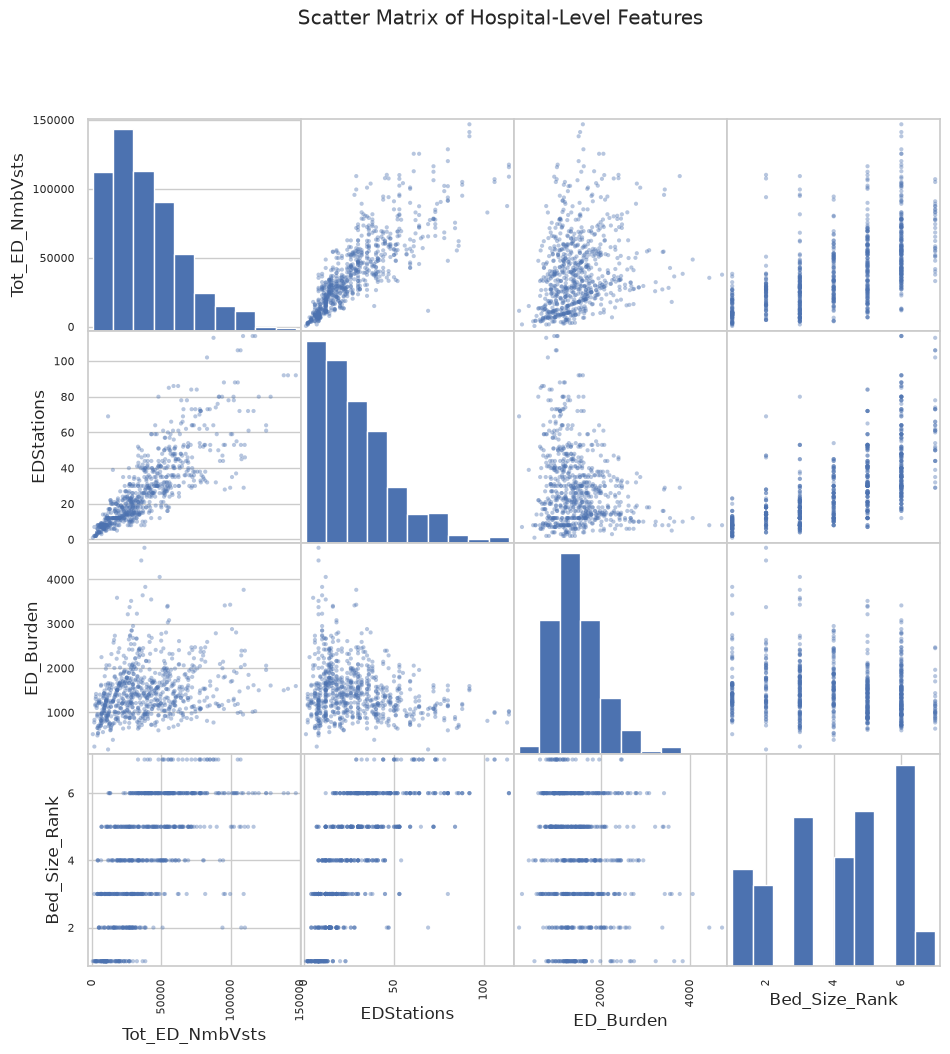

In [27]:
_ = pd.plotting.scatter_matrix(hosp[["Tot_ED_NmbVsts", "EDStations", "ED_Burden", "Bed_Size_Rank"]],
                               figsize=(11, 11), alpha=0.4, diagonal="hist")
plt.suptitle("Scatter Matrix of Hospital-Level Features")
plt.show()

The scatter matrix shows the tight upward band between visits and stations and the stepped pattern of bed size rank against both. Burden forms a cloud against every other feature, which matches its weak correlations. For more control, the seaborn `pairplot` below adds the urban/rural designation as color.

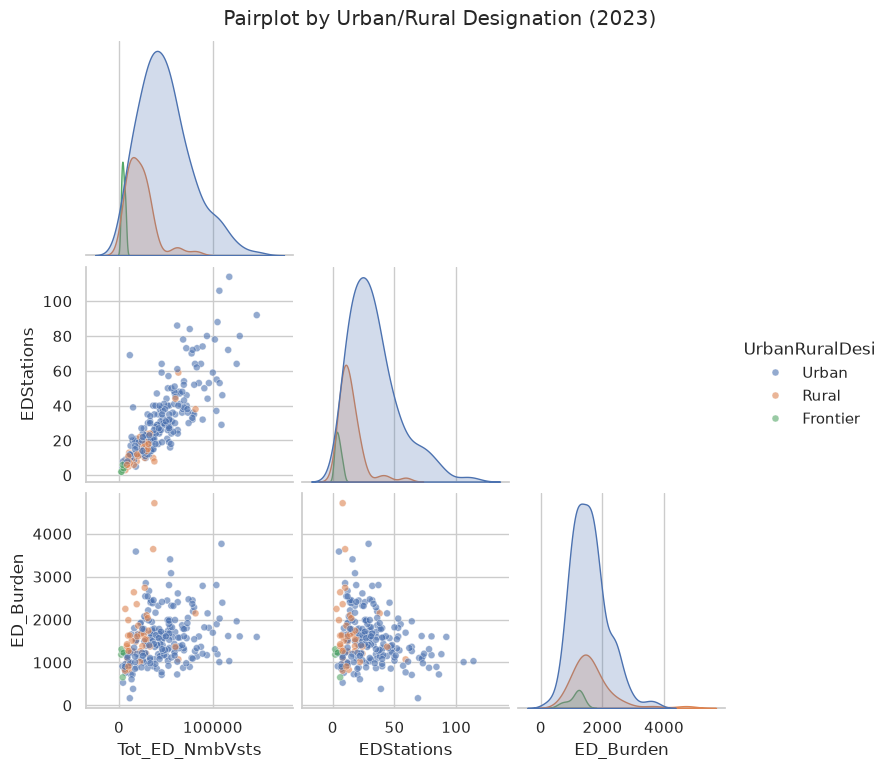

In [28]:
g = sns.pairplot(hosp_2023, vars=["Tot_ED_NmbVsts", "EDStations", "ED_Burden"],
                 hue="UrbanRuralDesi", hue_order=["Urban", "Rural", "Frontier"],
                 plot_kws={"alpha": 0.6, "s": 25}, corner=True)
g.figure.suptitle("Pairplot by Urban/Rural Designation (2023)", y=1.02)
plt.show()

Frontier hospitals (green) are confined to the low-visit, low-station corner. Rural hospitals overlap the smaller urban hospitals and reach burden values as high as urban ones. Across all years, rural hospitals have a slightly higher median burden (1,433) than urban hospitals (1,387), while frontier hospitals are lowest (1,154). Rural EDs are small, but they are not under-used.

## 6. Outliers and Data Cleaning

We examine each cause of outliers in Table 6.6.2 and state what we found and how we handled it.

### 6.1 Data processing error: "N/A" read as missing in `system`

The `system` column uses the text "N/A" for hospitals that do not belong to a health system. With default settings, pandas converts "N/A" to a missing value, which makes 28% of rows look incomplete.

In [29]:
default_read = pd.read_csv(source, encoding="utf-8-sig")
print("Missing 'system' with pandas defaults:  ", default_read["system"].isna().sum())
print("Missing 'system' with our explicit read:", data["system"].isna().sum())
print("Rows labeled 'No System':              ", (data["system"] == "No System").sum())

Missing 'system' with pandas defaults:   3590
Missing 'system' with our explicit read: 0
Rows labeled 'No System':               3590


Cleaning: we redid the read with `keep_default_na=False, na_values=[""]` so only truly empty cells count as missing, and relabeled "N/A" as "No System." The value is meaningful (independent hospital), not missing, and it is the most common system value.

### 6.2 Data processing error: duplicated hospital values in the long format

An earlier draft of this notebook computed z-scores of visits per station on all 12,849 rows. Because each hospital-year repeats 17 times, the outlier list was inflated. We redid the calculation on `hosp`.

In [30]:
long_ratio = data["Tot_ED_NmbVsts"] / data["EDStations"]
long_z = (long_ratio - long_ratio.mean()) / long_ratio.std()
long_flags = data.loc[long_z.abs() > 3, ["oshpd_id", "year"]]

hosp_z = (hosp["ED_Burden"] - hosp["ED_Burden"].mean()) / hosp["ED_Burden"].std()

print("|z| > 3 on the 12,849-row data:", len(long_flags), "rows")
print("  ...which are only", len(long_flags.drop_duplicates()), "distinct hospital-years")
print("|z| > 3 on hosp (correct unit):", (hosp_z.abs() > 3).sum(), "hospital-years")

|z| > 3 on the 12,849-row data: 238 rows
  ...which are only 14 distinct hospital-years
|z| > 3 on hosp (correct unit): 14 hospital-years


The earlier 238 "outliers" were really 14 hospital-years, each counted about 17 times. Cleaning: we redid the manipulation by de-duplicating to one row per hospital-year before computing any hospital-level statistic. This also corrected some earlier visual impressions. Once each hospital counts once, teaching hospitals and urban hospitals are not the most burdened groups (Sections 3.3 and 5.3).

### 6.3 Missing data: one hospital-year without a station count

In [31]:
el_monte = hosp[hosp["oshpd_id"] == hosp.loc[hosp["EDStations"].isna(), "oshpd_id"].iloc[0]]
el_monte[["FacilityName2", "year", "Tot_ED_NmbVsts", "EDStations", "ED_Burden"]]

,FacilityName2,year,Tot_ED_NmbVsts,EDStations,ED_Burden
60,Greater El Monte Community Hospital,2022,20914,NaN,NaN
571,Greater El Monte Community Hospital,2021,16357,9.0,1817.444444


Greater El Monte Community Hospital reports 9 stations in 2021 and no value in 2022, and it does not appear in 2023. We could fill 2022 with 9, but station counts do change between years (Section 6.4), so that would be an assumption, not an inference. Cleaning: we keep the row for visit-count analysis and exclude it only from burden calculations, which pandas does automatically by skipping NaN.

### 6.4 Possible data entry errors: large year-to-year station changes

Most hospitals report the same number of stations every year. A few change sharply, which could be a real expansion or closure, or an entry error.

In [32]:
stations_wide = hosp.pivot(index="oshpd_id", columns="year", values="EDStations")
change = (stations_wide[2023] / stations_wide[2022]).dropna()
names = hosp.drop_duplicates("oshpd_id", keep="last").set_index("oshpd_id")["FacilityName2"]

print("Share of hospitals with identical station counts in 2022 and 2023:", round((change == 1).mean(), 3))
flagged = change[(change <= 0.67) | (change >= 1.5)].index
review = stations_wide.loc[flagged].assign(Facility=names.loc[flagged])
review[["Facility", 2021, 2022, 2023]]

Share of hospitals with identical station counts in 2022 and 2023: 0.824


year,Facility,2021,2022,2023
oshpd_id,,,,
106334589,Loma Linda University Medical Center – Murrieta,NaN,80.0,37.0
106370714,Grossmont Hospital,102.0,113.0,74.0
106574010,Sutter Davis Hospital,11.0,11.0,23.0


About 82% of hospitals report the same station count in 2022 and 2023. The hospitals above changed by at least a third, for example Loma Linda University Medical Center – Murrieta (80 to 37) and Sutter Davis Hospital (11 to 23). The dataset gives no way to tell a real change from a keying error, so the intended value cannot be inferred. Cleaning: we do not alter these values. We flag them, and in modeling we will check whether results change when they are excluded.

### 6.5 Measurement error: coordinates differ slightly between years

In [33]:
lat_wide = hosp.pivot(index="oshpd_id", columns="year", values="LATITUDE")
lon_wide = hosp.pivot(index="oshpd_id", columns="year", values="LONGITUDE")

print("Hospitals with identical latitude 2021 vs 2022:", round((lat_wide[2021] == lat_wide[2022]).mean(), 3))
print("Hospitals with identical latitude 2022 vs 2023:", round((lat_wide[2022] == lat_wide[2023]).mean(), 3))
print("Largest 2022-2023 shift (degrees): lat", round((lat_wide[2023] - lat_wide[2022]).abs().max(), 4),
      "| lon", round((lon_wide[2023] - lon_wide[2022]).abs().max(), 4))

Hospitals with identical latitude 2021 vs 2022: 0.737
Hospitals with identical latitude 2022 vs 2023: 0.0
Largest 2022-2023 shift (degrees): lat 0.0197 | lon 0.0181


Every hospital present in both 2022 and 2023 has a slightly different coordinate in 2023, and the 2021 and 2022 values match for about 74% of hospitals. This pattern points to the 2023 coordinates being re-geocoded, not to hospitals moving. The largest shift is about 0.02°, roughly 2 km, and the typical shift is far smaller. Cleaning: the difference is too small to affect a statewide map, so we keep the values. For mapping in later steps we will use one coordinate per hospital (its most recent) so each facility plots at a single point.

In [34]:
latest_coords = (hosp.sort_values("year").groupby("oshpd_id")[["LATITUDE", "LONGITUDE"]].last()
                 .rename(columns={"LATITUDE": "LAT_STD", "LONGITUDE": "LON_STD"}))
hosp = hosp.merge(latest_coords, left_on="oshpd_id", right_index=True, how="left")
print("Coordinates per hospital after standardizing:",
      hosp.groupby("oshpd_id")[["LAT_STD", "LON_STD"]].nunique().max().to_dict())

Coordinates per hospital after standardizing: {'LAT_STD': 1, 'LON_STD': 1}


### 6.6 Sampling error: different populations and an unbalanced panel

Two issues come from combining different groups:

1. Hospitals are not all present every year. The check below shows how many years each hospital appears.
2. Burden values that look extreme statewide may be normal within their own group. Frontier, rural, and urban EDs serve very different populations.

In [35]:
print("Years present per hospital:\n", hosp.groupby("oshpd_id")["year"].nunique().value_counts().sort_index().to_string())
print()
print(hosp.groupby("UrbanRuralDesi")["ED_Burden"].describe()[["count", "25%", "50%", "75%", "max"]].round(0))

Years present per hospital:
 year
1     33
2     68
3    196

                count     25%     50%     75%     max
UrbanRuralDesi                                       
Frontier         23.0   801.0  1154.0  1235.0  1601.0
Rural           144.0  1210.0  1433.0  1744.0  4714.0
Urban           589.0  1069.0  1387.0  1784.0  4056.0


Only 196 of the 297 hospitals appear in all three years; 68 appear in two and 33 in one. Any trend analysis (learning question 3) must use hospitals present in every year, or it will mix real change with hospitals entering and leaving the data. Burden distributions also differ by setting: frontier hospitals have a median of 1,154 and a maximum near 1,700, while urban and rural EDs reach well above 4,000. Cleaning: we will judge outliers within each urban/rural group and include `UrbanRuralDesi` as a feature, instead of treating the state as one population.

### 6.7 Natural outliers: very high ED burden

In [36]:
burden_flags, _, high_fence = iqr_outliers(hosp["ED_Burden"].dropna())
natural = hosp.loc[burden_flags.index].sort_values("ED_Burden", ascending=False)

print(f"Upper fence: {high_fence:,.0f} visits per station; {len(natural)} hospital-years from "
      f"{natural['oshpd_id'].nunique()} hospitals flagged\n")
print(natural[["FacilityName2", "year", "UrbanRuralDesi", "LICENSED_BED_SIZE",
               "Tot_ED_NmbVsts", "EDStations", "ED_Burden"]].head(10).round(0).to_string(index=False))

Upper fence: 2,767 visits per station; 26 hospital-years from 14 hospitals flagged

                             FacilityName2  year UrbanRuralDesi LICENSED_BED_SIZE  Tot_ED_NmbVsts  EDStations  ED_Burden
              St. Louise Regional Hospital  2023          Rural             50-99           37712         8.0     4714.0
              St. Louise Regional Hospital  2022          Rural             50-99           35422         8.0     4428.0
         John F. Kennedy Memorial Hospital  2022          Urban           100-149           48677        12.0     4056.0
                  Adventist Health Reedley  2022          Rural              1-49           38319        10.0     3832.0
Martin Luther King, Jr. Community Hospital  2023          Urban           100-149          109217        29.0     3766.0
                  Adventist Health Reedley  2023          Rural              1-49           36422        10.0     3642.0
                    Monterey Park Hospital  2023          Urban      

These hospitals are not errors. The same facilities appear in multiple years with consistent values. For example, St. Louise Regional Hospital reports 8 stations and about 35,000–38,000 visits in both 2022 and 2023. They are small and mid-sized EDs carrying unusually high volume, exactly the facilities our resource-allocation goal is meant to find. Table 6.6.2 says models should be checked for stability with and without natural outliers, so we do that below.

In [37]:
without = hosp.drop(index=burden_flags.index)

stability = pd.DataFrame({
    "With outliers": [hosp["ED_Burden"].mean(), hosp["ED_Burden"].median(),
                      hosp["Tot_ED_NmbVsts"].corr(hosp["EDStations"])],
    "Without outliers": [without["ED_Burden"].mean(), without["ED_Burden"].median(),
                         without["Tot_ED_NmbVsts"].corr(without["EDStations"])]},
    index=["Mean ED burden", "Median ED burden", "r(visits, stations)"])
stability.round(3)

,With outliers,Without outliers
Mean ED burden,1486.385,1419.667
Median ED burden,1384.959,1365.690
"r(visits, stations)",0.829,0.851


Removing the 26 high-burden hospital-years lowers mean burden from about 1,486 to 1,420 but moves the median by less than 20 (1,385 to 1,366), and the visits–stations correlation rises only slightly (0.829 to 0.851). Results are stable, and the median is the better summary of a typical ED. Cleaning: we keep natural outliers in the data, report medians for burden, and will fit models with and without them.

### 6.8 Cleaned hospital-level dataset

We collect the cleaning decisions into one dataframe for the modeling notebooks.

In [38]:
hosp_clean = hosp.copy()

stations_changed = set(flagged)
hosp_clean["Station_Change_Flag"] = hosp_clean["oshpd_id"].isin(stations_changed)
hosp_clean["Burden_Outlier_Flag"] = hosp_clean.index.isin(burden_flags.index)
hosp_clean["In_All_Years"] = hosp_clean["oshpd_id"].map(hosp.groupby("oshpd_id")["year"].nunique().eq(3))

print(hosp_clean.shape)
print(hosp_clean[["Station_Change_Flag", "Burden_Outlier_Flag", "In_All_Years"]].sum().to_string())
print("Missing ED_Burden (excluded from burden analysis):", hosp_clean["ED_Burden"].isna().sum())

(757, 22)
Station_Change_Flag      8
Burden_Outlier_Flag     26
In_All_Years           588
Missing ED_Burden (excluded from burden analysis): 1


## Summary of Findings

1. Structure: The 12,849 rows describe 757 hospital-years for 297 California hospitals (2021–2023) across 17 diagnosis categories. Hospital-level analysis must use one row per hospital-year, and category counts overlap, so they cannot be summed.
2. Size and usage: ED visits are strongly correlated with stations (r = 0.83) and moderately with bed size (r = 0.60). Bigger hospitals are busier, but size explains only part of usage.
3. Burden: Visits per station is right-skewed with a median of 1,385. It is weakly related to size, rose from 2021 to 2023, and is highest at a set of small-to-mid-sized urban and rural EDs, not at the largest or teaching hospitals.
4. Geography: Hospitals cluster in Southern California and the Bay Area. High-burden EDs appear in several regions, so location must be combined with facility features.
5. Data quality: We corrected a parsing issue ("N/A"), removed duplicate counting, isolated one missing station count, flagged unverifiable station changes, standardized coordinates, and kept natural outliers with a stability check.

Next steps: `regression.ipynb` will model total ED visits and ED burden from bed size, stations, ownership, teaching status, setting, and location, with and without the flagged outliers.